# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [1]:
import random

class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def __str__(self):
        return f"{self.rank} of {self.suit}"


class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.shuffle()

    def shuffle(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6", "7",
                 "8", "9", "10", "J", "Q", "K"]

        self.cards = [
            Card(rank, suit)
            for _ in range(self.num_decks)
            for suit in suits
            for rank in ranks
        ]

        random.shuffle(self.cards)

        # Insert the plastic card at a random position
        position = random.randint(1, len(self.cards) - 1)
        self.cards.insert(position, "PLASTIC")

    def draw(self):
        if not self.cards:
            self.shuffle()

        card = self.cards.pop()

        if card == "PLASTIC":
            print("Plastic card reached! Reshuffling before next deal.")
            self.shuffle()
            card = self.cards.pop()

        return card


# Test the deck
deck = Deck(6)

print("Total cards:", len(deck.cards))
print("Drawing 5 cards:")

for i in range(5):
    print(deck.draw())

print("Cards remaining:", len(deck.cards))

Total cards: 313
Drawing 5 cards:
10 of Diamonds
A of Hearts
6 of Hearts
9 of Spades
3 of Hearts
Cards remaining: 308


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [2]:
class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def __str__(self):
        pass

    def get_value(self):
        pass


class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.reshuffle_needed = False

    def shuffle(self):
        pass

    def draw(self):
        pass


class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        pass

    def get_value(self):
        pass

    def is_bust(self):
        pass

    def clear(self):
        pass


class Player:
    def __init__(self, name, chips=500):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    def place_bet(self, amount):
        pass

    def hit(self, deck):
        pass

    def stay(self):
        pass

    def decide(self, dealer_card=None):
        pass


class Dealer(Player):
    def __init__(self):
        super().__init__("Dealer", 0)

    def decide(self, dealer_card=None):
        pass


class HumanPlayer(Player):
    def decide(self, dealer_card=None):
        pass


class CountingPlayer(Player):
    def __init__(self, name, chips=500, threshold=-2):
        super().__init__(name, chips)
        self.running_count = 0
        self.threshold = threshold

    def update_count(self, card):
        pass

    def decide(self, dealer_card=None):
        pass


class BlackjackGame:
    def __init__(self, players, num_decks=6):
        self.players = players
        self.dealer = Dealer()
        self.deck = Deck(num_decks)
        self.round_number = 0

    def deal_cards(self):
        pass

    def player_turn(self, player):
        pass

    def dealer_turn(self):
        pass

    def determine_winner(self, player):
        pass

    def play_round(self):
        pass

    def play_multiple_rounds(self, rounds=50):
        pass


print("All Blackjack class skeletons created successfully!")


All Blackjack class skeletons created successfully!


4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [3]:
import random

# Card class
class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def __str__(self):
        return f"{self.rank} of {self.suit}"

    def get_value(self):
        if self.rank in ["J", "Q", "K"]:
            return 10
        if self.rank == "A":
            return 11
        return int(self.rank)


# Deck class
class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.reshuffle_needed = False
        self.shuffle()

    def shuffle(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6", "7",
                 "8", "9", "10", "J", "Q", "K"]

        self.cards = [
            Card(rank, suit)
            for _ in range(self.num_decks)
            for suit in suits
            for rank in ranks
        ]

        random.shuffle(self.cards)

        # Plastic card placed randomly in the shoe
        position = random.randint(
            len(self.cards) // 2,
            len(self.cards) - 1
        )
        self.cards.insert(position, "PLASTIC")
        self.reshuffle_needed = False

    def draw(self):
        # A plastic card is removed and signals a future shuffle.
        while self.cards:
            card = self.cards.pop()

            if card == "PLASTIC":
                self.reshuffle_needed = True
                continue

            return card

        # Emergency reshuffle if the shoe is exhausted.
        self.shuffle()
        return self.cards.pop()


# Hand class
class Hand:
    def __init__(self):
        self.cards = []

    def add_card(self, card):
        self.cards.append(card)

    def get_value(self):
        total = sum(card.get_value() for card in self.cards)
        aces = sum(card.rank == "A" for card in self.cards)

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def is_bust(self):
        return self.get_value() > 21

    def clear(self):
        self.cards = []

    def show(self):
        return ", ".join(str(card) for card in self.cards)


# Player class
class Player:
    def __init__(self, name, chips=500):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.bet = 0

    def place_bet(self, amount):
        if amount <= 0 or amount > self.chips:
            raise ValueError("Invalid bet amount.")

        self.bet = amount
        self.chips -= amount

    def hit(self, deck):
        self.hand.add_card(deck.draw())

    def stay(self):
        return "stay"

    def decide(self, dealer_card=None):
        return "stay"


# Dealer class
class Dealer(Player):
    def __init__(self):
        super().__init__("Dealer", 0)

    def decide(self, dealer_card=None):
        if self.hand.get_value() < 17:
            return "hit"
        return "stay"


# Human player class
class HumanPlayer(Player):
    def decide(self, dealer_card=None):
        while True:
            choice = input("Hit or stay? (h/s): ").lower().strip()

            if choice in ["h", "hit"]:
                return "hit"

            if choice in ["s", "stay"]:
                return "stay"

            print("Please enter h or s.")


# Blackjack game class
class BlackjackGame:
    def __init__(self, players, num_decks=6):
        self.players = players
        self.dealer = Dealer()
        self.deck = Deck(num_decks)
        self.round_number = 0

    def deal_cards(self):
        self.dealer.hand.clear()

        for player in self.players:
            player.hand.clear()

        # Deal two cards to each player and dealer
        for _ in range(2):
            for player in self.players:
                player.hit(self.deck)

            self.dealer.hit(self.deck)

    def player_turn(self, player):
        while not player.hand.is_bust():
            print(f"\n{player.name}: {player.hand.show()}")
            print("Hand value:", player.hand.get_value())

            if player.hand.get_value() == 21:
                break

            action = player.decide(self.dealer.hand.cards[0])

            if action == "hit":
                player.hit(self.deck)
            else:
                break

    def dealer_turn(self):
        print("\nDealer's turn")
        print("Dealer:", self.dealer.hand.show())

        while self.dealer.decide() == "hit":
            self.dealer.hit(self.deck)
            print("Dealer hits:", self.dealer.hand.cards[-1])

        print("Dealer final value:",
              self.dealer.hand.get_value())

    def determine_winner(self, player):
        player_value = player.hand.get_value()
        dealer_value = self.dealer.hand.get_value()

        player_blackjack = (
            len(player.hand.cards) == 2 and player_value == 21
        )
        dealer_blackjack = (
            len(self.dealer.hand.cards) == 2
            and dealer_value == 21
        )

        if player.hand.is_bust():
            result = "Lose"

        elif player_blackjack and not dealer_blackjack:
            result = "Blackjack!"
            # 3:2 blackjack payout, including original bet
            player.chips += player.bet * 2.5

        elif dealer_blackjack and not player_blackjack:
            result = "Lose"

        elif self.dealer.hand.is_bust():
            result = "Win"
            player.chips += player.bet * 2

        elif player_value > dealer_value:
            result = "Win"
            player.chips += player.bet * 2

        elif player_value == dealer_value:
            result = "Push"
            player.chips += player.bet

        else:
            result = "Lose"

        player.bet = 0
        return result

    def play_round(self):
        if self.deck.reshuffle_needed or len(self.deck.cards) < 30:
            print("Reshuffling the deck...")
            self.deck.shuffle()

        self.round_number += 1
        print(f"\n========== ROUND {self.round_number} ==========")

        for player in self.players:
            if player.chips < 10:
                print(f"{player.name} has insufficient chips.")
                return

            player.place_bet(10)

        self.deal_cards()

        print("Dealer showing:", self.dealer.hand.cards[0])

        for player in self.players:
            self.player_turn(player)

        # Dealer only draws if at least one player has not busted
        if any(not p.hand.is_bust() for p in self.players):
            self.dealer_turn()
        else:
            print("\nAll players busted.")

        for player in self.players:
            result = self.determine_winner(player)
            print(f"{player.name}: {result}")
            print(f"Chips remaining: {player.chips}")

    def play_multiple_rounds(self, rounds=50):
        for _ in range(rounds):
            if all(player.chips < 10 for player in self.players):
                print("No players have enough chips.")
                break

            self.play_round()


# Create a human player and start the game
human = HumanPlayer("Human Player", 500)
game = BlackjackGame([human], num_decks=6)

game.play_multiple_rounds(3)



========== ROUND 1 ==========
Dealer showing: 6 of Hearts

Human Player: 8 of Hearts, J of Spades
Hand value: 18


Hit or stay? (h/s):  Hit



All players busted.
Human Player: Lose
Chips remaining: 490

========== ROUND 2 ==========
Dealer showing: 7 of Hearts

Human Player: 10 of Clubs, 3 of Spades
Hand value: 13


Hit or stay? (h/s):  Hit



Human Player: 10 of Clubs, 3 of Spades, 5 of Clubs
Hand value: 18


...


All players busted.
Human Player: Lose
Chips remaining: 480

========== ROUND 3 ==========
Dealer showing: 8 of Spades

Human Player: Q of Spades, 4 of Clubs
Hand value: 14


Hit or stay? (h/s):  Hit



Human Player: Q of Spades, 4 of Clubs, 4 of Hearts
Hand value: 18


Hit or stay? (h/s):  stay



Dealer's turn
Dealer: 8 of Spades, A of Hearts
Dealer final value: 19
Human Player: Lose
Chips remaining: 470


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [4]:
# Computer players follow the dealer's strategy:
# Hit below 17 and stay at 17 or higher.
class ComputerPlayer(Player):
    def decide(self, dealer_card=None):
        if self.hand.get_value() < 17:
            return "hit"
        return "stay"


# Create 3 computer players
player1 = ComputerPlayer("Computer Player 1", 500)
player2 = ComputerPlayer("Computer Player 2", 500)
player3 = ComputerPlayer("Computer Player 3", 500)

# Create a game with 6 decks
test_game = BlackjackGame(
    [player1, player2, player3],
    num_decks=6
)

# Play 5 rounds
test_game.play_multiple_rounds(5)

# Display final results
print("FINAL RESULTS:")

for player in test_game.players:
    print(f"{player.name}: ${player.chips:.2f}")
    print(f"Total winnings: ${player.chips - 500:.2f}")



========== ROUND 1 ==========
Dealer showing: 9 of Diamonds

Computer Player 1: 7 of Diamonds, 6 of Diamonds
Hand value: 13

Computer Player 1: 7 of Diamonds, 6 of Diamonds, 2 of Hearts
Hand value: 15

Computer Player 2: J of Hearts, 8 of Hearts
Hand value: 18

Computer Player 3: 8 of Hearts, A of Spades
Hand value: 19

Dealer's turn
Dealer: 9 of Diamonds, Q of Hearts
Dealer final value: 19
Computer Player 1: Lose
Chips remaining: 490
Computer Player 2: Lose
Chips remaining: 490
Computer Player 3: Push
Chips remaining: 500

========== ROUND 2 ==========
Dealer showing: 4 of Clubs

Computer Player 1: 7 of Spades, 2 of Diamonds
Hand value: 9

Computer Player 1: 7 of Spades, 2 of Diamonds, 3 of Clubs
Hand value: 12

Computer Player 1: 7 of Spades, 2 of Diamonds, 3 of Clubs, A of Clubs
Hand value: 13

Computer Player 1: 7 of Spades, 2 of Diamonds, 3 of Clubs, A of Clubs, 7 of Clubs
Hand value: 20

Computer Player 2: 10 of Hearts, 4 of Spades
Hand value: 14

Computer Player 3: Q of Clubs, 

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [5]:
class CountingPlayer(Player):
    def __init__(self, name, chips=500, threshold=-2):
        super().__init__(name, chips)
        self.running_count = 0
        self.threshold = threshold
        self.seen_cards = set()

    def update_count(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            self.running_count += 1
        elif card.rank in ["10", "J", "Q", "K", "A"]:
            self.running_count -= 1

    def observe_cards(self, players, dealer):
        # Count only cards visible so far
        for player in players:
            for card in player.hand.cards:
                if id(card) not in self.seen_cards:
                    self.update_count(card)
                    self.seen_cards.add(id(card))

        # Count dealer's visible card only
        if dealer.hand.cards:
            card = dealer.hand.cards[0]
            if id(card) not in self.seen_cards:
                self.update_count(card)
                self.seen_cards.add(id(card))

    def decide(self, dealer_card=None):
        if self.running_count < self.threshold:
            return "hit"
        return "stay"


# Test card counting
counter = CountingPlayer("Card Counter", 500, threshold=-2)

test_cards = [
    Card("2", "Hearts"),
    Card("5", "Clubs"),
    Card("K", "Spades"),
    Card("9", "Diamonds"),
    Card("A", "Hearts")
]

print("Testing Card Counting Strategy\n")

for card in test_cards:
    counter.update_count(card)
    print(f"Card: {card}")
    print(f"Running count: {counter.running_count}")
    print(f"Decision: {counter.decide()}\n")


Testing Card Counting Strategy

Card: 2 of Hearts
Running count: 1
Decision: stay

Card: 5 of Clubs
Running count: 2
Decision: stay

Card: K of Spades
Running count: 1
Decision: stay

Card: 9 of Diamonds
Running count: 1
Decision: stay

Card: A of Hearts
Running count: 0
Decision: stay



7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [6]:
import random

random.seed(42)

STARTING_CHIPS = 500
BET = 10
MAX_ROUNDS = 50

class StrategyPlayer(CountingPlayer):
    def decide(self, dealer_card=None):
        # Avoid drawing when already at 21 or busted
        if self.hand.get_value() >= 21:
            return "stay"

        if self.running_count < self.threshold:
            return "hit"

        return "stay"


# Create one strategy player and three regular players
strategy = StrategyPlayer("Card Counter", STARTING_CHIPS, -2)

regular_players = [
    ComputerPlayer("Computer Player 1", STARTING_CHIPS),
    ComputerPlayer("Computer Player 2", STARTING_CHIPS),
    ComputerPlayer("Computer Player 3", STARTING_CHIPS)
]

players = [strategy] + regular_players
game = BlackjackGame(players, num_decks=6)

# Keep track of results
rounds_played = 0

for round_num in range(1, MAX_ROUNDS + 1):

    if strategy.chips < BET:
        print("Card-counting player is out of money.")
        break

    # Reshuffle when the plastic card was reached
    if game.deck.reshuffle_needed or len(game.deck.cards) < 30:
        game.deck.shuffle()
        strategy.running_count = 0
        strategy.seen_cards.clear()

    # Only include players who can afford the bet
    active_players = [
        p for p in players if p.chips >= BET
    ]

    # Clear hands and place bets
    game.dealer.hand.clear()

    for player in players:
        player.hand.clear()
        player.bet = 0

    for player in active_players:
        player.place_bet(BET)

    # Deal two cards
    for _ in range(2):
        for player in active_players:
            player.hit(game.deck)
        game.dealer.hit(game.deck)

    # Count all initially visible cards
    strategy.observe_cards(active_players, game.dealer)

    # Players take turns
    for player in active_players:
        while player.hand.get_value() < 21:

            if isinstance(player, StrategyPlayer):
                strategy.observe_cards(active_players, game.dealer)

            action = player.decide(game.dealer.hand.cards[0])

            if action != "hit":
                break

            player.hit(game.deck)

            # Count newly revealed cards
            strategy.observe_cards(active_players, game.dealer)

    # Dealer plays if anyone is still in the game
    if any(not p.hand.is_bust() for p in active_players):
        while game.dealer.hand.get_value() < 17:
            game.dealer.hit(game.deck)

            # Count newly revealed dealer cards
            strategy.observe_cards(active_players, game.dealer)

    # Reveal and count the dealer's hidden card
    for card in game.dealer.hand.cards:
        if id(card) not in strategy.seen_cards:
            strategy.update_count(card)
            strategy.seen_cards.add(id(card))

    # Determine results and update chips
    for player in active_players:
        game.determine_winner(player)

    rounds_played += 1

    # Quiet mode: only print every 10 rounds
    if round_num % 10 == 0:
        print(f"After round {round_num}: "
              f"Card Counter = ${strategy.chips:.2f}")


# Final results
print("FINAL RESULTS:")
print("Rounds played:", rounds_played)
print("Starting chips: $500.00")
print()

for player in players:
    winnings = player.chips - STARTING_CHIPS

    print(f"{player.name}")
    print(f"  Final chips: ${player.chips:.2f}")
    print(f"  Net winnings: ${winnings:+.2f}")
    print()

print("Strategy player's total winnings:",
      f"${strategy.chips - STARTING_CHIPS:+.2f}")


After round 10: Card Counter = $470.00
After round 20: Card Counter = $470.00
After round 30: Card Counter = $420.00
After round 40: Card Counter = $410.00
After round 50: Card Counter = $360.00

========== FINAL RESULTS ==========
Rounds played: 50
Starting chips: $500.00

Card Counter
  Final chips: $360.00
  Net winnings: $-140.00

Computer Player 1
  Final chips: $560.00
  Net winnings: $+60.00

Computer Player 2
  Final chips: $475.00
  Net winnings: $-25.00

Computer Player 3
  Final chips: $525.00
  Net winnings: $+25.00

Strategy player's total winnings: $-140.00


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


SIMULATION RESULTS:
Number of games: 100
Maximum rounds per game: 50

Average net winnings per game: $-157.05
Average winnings per round: $-3.14
Standard deviation of 50-round net winnings: $69.12

Probability of net winning: 1.00%
Probability of net losing: 99.00%
Probability of breaking even: 0.00%


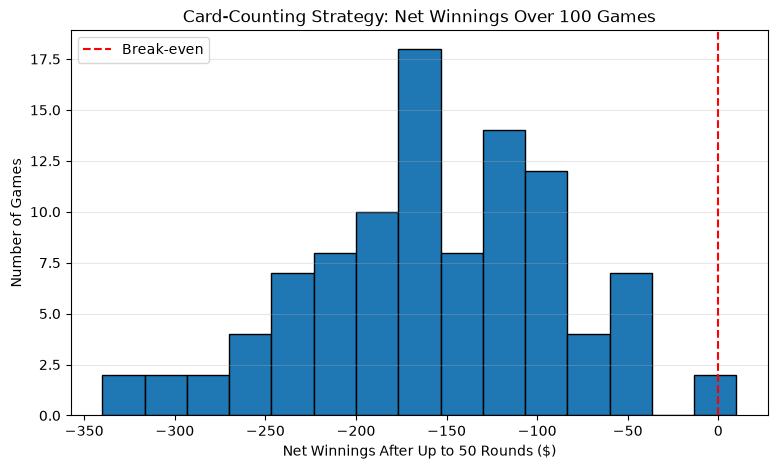

In [7]:

# Part 8: Run 100 games of 50 rounds

import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(42)

NUM_GAMES = 100
ROUNDS = 50
STARTING_CHIPS = 500
BET = 10

ending_chips = []
rounds_per_game = []

for game_num in range(NUM_GAMES):

    # Create new players for every game
    strategy = StrategyPlayer("Card Counter", STARTING_CHIPS, -2)

    regular_players = [
        ComputerPlayer("Computer 1", STARTING_CHIPS),
        ComputerPlayer("Computer 2", STARTING_CHIPS),
        ComputerPlayer("Computer 3", STARTING_CHIPS)
    ]

    players = [strategy] + regular_players
    game = BlackjackGame(players, num_decks=6)

    rounds_played = 0

    for round_num in range(ROUNDS):

        if strategy.chips < BET:
            break

        # Reshuffle the deck if needed
        if game.deck.reshuffle_needed or len(game.deck.cards) < 30:
            game.deck.shuffle()
            strategy.running_count = 0
            strategy.seen_cards.clear()

        active_players = [
            p for p in players if p.chips >= BET
        ]

        game.dealer.hand.clear()

        for player in players:
            player.hand.clear()
            player.bet = 0

        for player in active_players:
            player.place_bet(BET)

        # Deal initial cards
        for _ in range(2):
            for player in active_players:
                player.hit(game.deck)
            game.dealer.hit(game.deck)

        strategy.observe_cards(active_players, game.dealer)

        # Player turns
        for player in active_players:
            while player.hand.get_value() < 21:

                strategy.observe_cards(active_players, game.dealer)

                action = player.decide(game.dealer.hand.cards[0])

                if action != "hit":
                    break

                player.hit(game.deck)
                strategy.observe_cards(active_players, game.dealer)

        # Dealer's turn
        if any(not p.hand.is_bust() for p in active_players):
            while game.dealer.hand.get_value() < 17:
                game.dealer.hit(game.deck)
                strategy.observe_cards(active_players, game.dealer)

        # Count the dealer's hidden card
        for card in game.dealer.hand.cards:
            if id(card) not in strategy.seen_cards:
                strategy.update_count(card)
                strategy.seen_cards.add(id(card))

        # Determine winners
        for player in active_players:
            game.determine_winner(player)

        rounds_played += 1

    ending_chips.append(strategy.chips)
    rounds_per_game.append(rounds_played)


# Calculate results
ending_chips = np.array(ending_chips)
rounds_per_game = np.array(rounds_per_game)

net_winnings = ending_chips - STARTING_CHIPS

average_winnings = np.mean(net_winnings)
average_per_round = (
    np.sum(net_winnings) / np.sum(rounds_per_game)
)
standard_deviation = np.std(net_winnings, ddof=1)

prob_win = np.mean(net_winnings > 0)
prob_lose = np.mean(net_winnings < 0)
prob_tie = np.mean(net_winnings == 0)

# Print results
print("SIMULATION RESULTS:")
print("Number of games:", NUM_GAMES)
print("Maximum rounds per game:", ROUNDS)

print(f"\nAverage net winnings per game: ${average_winnings:.2f}")
print(f"Average winnings per round: ${average_per_round:.2f}")
print(f"Standard deviation of 50-round net winnings: ${standard_deviation:.2f}")

print(f"\nProbability of net winning: {prob_win:.2%}")
print(f"Probability of net losing: {prob_lose:.2%}")
print(f"Probability of breaking even: {prob_tie:.2%}")

# Create histogram
plt.figure(figsize=(9, 5))
plt.hist(net_winnings, bins=15, edgecolor="black")
plt.axvline(0, color="red", linestyle="--", label="Break-even")

plt.title("Card-Counting Strategy: Net Winnings Over 100 Games")
plt.xlabel("Net Winnings After Up to 50 Rounds ($)")
plt.ylabel("Number of Games")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

Answer: I tested seven thresholds and found that (-5, -3, -2, -1, 0, 1, and 3) had the hisghest average winnings. However, more simulations are needed to confirm that it is the best threshold.

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

STRATEGY COMPARISON: 
Basic Strategy Average Winnings: $-13.35
Regular Strategy Average Winnings: $-27.15
Difference: $+13.80

Basic Strategy Win Probability: 40.00%
Regular Strategy Win Probability: 35.00%


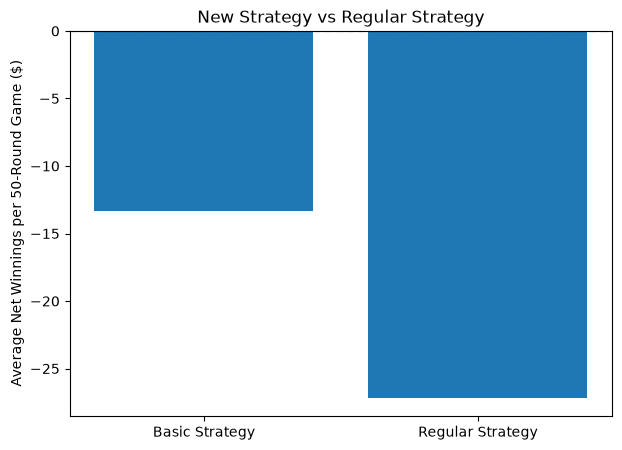

In [8]:
import random
import numpy as np
import matplotlib.pyplot as plt

class BasicStrategyPlayer(ComputerPlayer):
    def decide(self, dealer_card=None):
        total = self.hand.get_value()

        if total <= 11:
            return "hit"
        if total >= 17:
            return "stay"

        dealer_value = dealer_card.get_value()

        if 2 <= dealer_value <= 6:
            return "stay"
        return "hit"


NUM_GAMES = 100
ROUNDS = 50
STARTING_CHIPS = 500
BET = 10

basic_results = []
regular_results = []

for game_num in range(NUM_GAMES):
    random.seed(100 + game_num)

    basic = BasicStrategyPlayer("Basic Strategy", STARTING_CHIPS)
    regular = ComputerPlayer("Regular Strategy", STARTING_CHIPS)

    # Keep the two comparison players and two other
    # regular players at the same table.
    other1 = ComputerPlayer("Computer 2", STARTING_CHIPS)
    other2 = ComputerPlayer("Computer 3", STARTING_CHIPS)

    game = BlackjackGame(
        [basic, regular, other1, other2],
        num_decks=6
    )

    for round_num in range(ROUNDS):
        if game.deck.reshuffle_needed or len(game.deck.cards) < 30:
            game.deck.shuffle()

        active = [p for p in game.players if p.chips >= BET]
        if not active:
            break

        game.dealer.hand.clear()

        for player in game.players:
            player.hand.clear()
            player.bet = 0

        for player in active:
            player.place_bet(BET)

        # Deal two cards
        for _ in range(2):
            for player in active:
                player.hit(game.deck)
            game.dealer.hit(game.deck)

        # Player decisions
        for player in active:
            while player.hand.get_value() < 21:
                decision = player.decide(game.dealer.hand.cards[0])

                if decision == "stay":
                    break

                player.hit(game.deck)

        # Dealer's turn
        if any(not p.hand.is_bust() for p in active):
            while game.dealer.hand.get_value() < 17:
                game.dealer.hit(game.deck)

        # Calculate winnings
        for player in active:
            game.determine_winner(player)

    basic_results.append(basic.chips - STARTING_CHIPS)
    regular_results.append(regular.chips - STARTING_CHIPS)


basic_results = np.array(basic_results)
regular_results = np.array(regular_results)

basic_avg = np.mean(basic_results)
regular_avg = np.mean(regular_results)

print("STRATEGY COMPARISON: ")
print(f"Basic Strategy Average Winnings: ${basic_avg:.2f}")
print(f"Regular Strategy Average Winnings: ${regular_avg:.2f}")
print(f"Difference: ${basic_avg - regular_avg:+.2f}")

print(f"\nBasic Strategy Win Probability: "
      f"{np.mean(basic_results > 0):.2%}")
print(f"Regular Strategy Win Probability: "
      f"{np.mean(regular_results > 0):.2%}")

# Bar chart comparison
plt.figure(figsize=(7, 5))
plt.bar(
    ["Basic Strategy", "Regular Strategy"],
    [basic_avg, regular_avg]
)
plt.axhline(0, color="black", linestyle="--")
plt.ylabel("Average Net Winnings per 50-Round Game ($)")
plt.title("New Strategy vs Regular Strategy")
plt.show()


I created a new strategy that uses the player's hand value and the dealer's visible card to decide whether to hit or stay. After 100 simulated games, the new strategy had average winnings of -\$ 13.35 compared to -\$ 27.15 for the regular strategy, showing an improvement of $13.80. The new strategy performed better, with a 40% win probability compared to 35% for the regular strategy.